# Random Forest - Morphology Prediction (inverse problem)

Can the spatial distribution of star formation (**G, C, A, S**) predict a galaxy's global properties?

**How to read the results.** G/C/A/S are measured from Hα maps, so they partly encode *how* a galaxy was observed
(redshift, seeing/resolution) as well as the galaxy itself. The raw score of a G/C/A/S-only model therefore mixes
real signal with observational/selection effects. Every run fits three feature sets on identical galaxies and identical CV splits:

| Model set | Features | Question it answers |
|---|---|---|
| **Baseline** | observational `controls` (+ optional `condition_on`) | how much of the target is predictable *without* morphology? |
| **GCAS** | G, C, A, S | the raw (confounded) predictive power of morphology |
| **GCAS + Baseline** | both | the full model |

The **headline number is the gain**: score(GCAS + Baseline) − score(Baseline), tested against a permutation null in which
G/C/A/S are shuffled jointly. The detailed plots further down (pred vs actual, importances, feature relationships)
all use the **GCAS + Baseline** model; control/conditioning features are hatched in the importance plots because their
importances are not interpreted physically.

Categorical targets (`spectral_class`, `environment`) switch the notebook to classification automatically
(scored by ROC AUC; chance = 0.5).

In [10]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns

from scipy.stats import pearsonr
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.linear_model import RidgeCV, LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold
from sklearn.inspection import permutation_importance
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error,
                             roc_auc_score, roc_curve, accuracy_score,
                             balanced_accuracy_score, confusion_matrix)

# ── Shared repo locations (sf_statistics/src/utils/paths.py) ─────────────────
import sys
from pathlib import Path
_here = Path.cwd().resolve()
REPO_ROOT = next(p for p in [_here, *_here.parents]
                 if (p / 'sf_statistics' / 'src' / 'utils' / 'paths.py').exists())
sys.path.insert(0, str(REPO_ROOT / 'sf_statistics'))
from src.utils.paths import ML_DATA_CSV, ML_IMPORTANCES_DIR, ML_MODEL_OUTPUTS_DIR

In [11]:
## ── CONFIGURATION ──
# This will be the section I can edit to change the model
# All subsequent cells read from CONFIG

CONFIG = {
    # ── Target ───────────────────────────────────────────────────────────────
    # Continuous (regression):      'delta_ms', 'log_sSFR', 'log_SFR', 'log_Mstar'
    # Categorical (classification): 'spectral_class', 'environment'  (switched automatically)
    'target': 'delta_ms',

    # Restrict to the full purity/quality-cut sample (in_full_sam == True)?
    'require_full_sam': True,

    # Spectral class sample: 'pure_SF', 'composite_SF' or 'both'
    # (must be 'both' when the target is spectral_class)
    'spectral_sample': 'both',

    # Subgroup: 'all', 'field' (GAMA) or 'cluster'
    'subgroup': 'all',

    # Seeing cut: None for no cut, or a float e.g. 2.0 (arcsec)
    'seeing_cut': None,

    # ── Feature groups ───────────────────────────────────────────────────────
    # Science features: the morphology metrics whose information content we're measuring
    'science_features': ['G', 'C', 'A', 'S'],

    # Observational controls: absorb redshift/resolution effects in how G/C/A/S are
    # measured. Their importances are NOT interpreted physically.
    # Options: 'z', 'seeing', 'n_res', 'ellip'
    # (n_res = re/seeing also carries real galaxy size, so it absorbs some physical signal)
    'controls': ['z', 'seeing'],

    # Physical conditioning: asks "do G/C/A/S add information at fixed X?"
    # e.g. ['log_Mstar'] when the target is delta_ms or log_sSFR.
    # Categorical columns (e.g. 'spectral_class') are encoded 0/1 automatically.
    'condition_on': [],

    # ── Hyperparameters ──────────────────────────────────────────────────────
    'n_estimators':      500,
    'max_features':      'sqrt',
    'max_depth':         None,
    'min_samples_leaf':  5,
    'min_samples_split': 2,
    'bootstrap':         True,
    'oob_score':         True,
    'class_weight':      'balanced',   # classification only (classes are imbalanced)

    # ── CV and reproducibility ───────────────────────────────────────────────
    'n_folds':     5,
    'cv_repeats':  5,     # repeats of the k-fold CV used for the three-model comparison
    'random_seed': 42,

    # ── Permutation importance ───────────────────────────────────────────────
    'perm_n_repeats': 10,

    # ── Permutation test of the GCAS gain ────────────────────────────────────
    'n_perm_test':            100,   # number of joint G/C/A/S shuffles; 0 to skip (~1 min at 100)
    'perm_test_n_estimators': 200,   # fewer trees keeps the test fast

    # ── I/O ─────────────────────────────────────────────────────────────────
    'data_path':    ML_DATA_CSV,
    'output_dir':   ML_MODEL_OUTPUTS_DIR / 'inverse' / 'random_forest',
    'save_outputs': True,            # save the permutation-test CSVs to output_dir

    # ── Shared thesis outputs (continuous targets only) ─────────────────────
    # importances/{ALGO}_morph_{target}.csv (+ _performance.csv), overwritten on each run of that target,
    # (read by ml/figures/make_morphology_importance_figures.py for the thesis figure)
    'save_importances': True,
    'importances_dir':  ML_IMPORTANCES_DIR,
}

# ── Categorical targets → classification (value = the class treated as positive) ──
CATEGORICAL_TARGETS = {
    'spectral_class': 'composite_SF',
    'environment':    'Cluster',
}

target = CONFIG['target']
TASK = 'classification' if target in CATEGORICAL_TARGETS else 'regression'

if TASK == 'classification':
    SCORE_NAME, SCORING, CHANCE_SCORE = 'ROC AUC', 'roc_auc', 0.5
else:
    SCORE_NAME, SCORING, CHANCE_SCORE = 'R²', 'r2', 0.0

# ── Feature groups and the three model sets ───────────────────────────────────
SCIENCE_FEATURES   = list(CONFIG['science_features'])
CONTROL_FEATURES   = list(CONFIG['controls'])
CONDITION_FEATURES = list(CONFIG['condition_on'])
BASELINE_FEATURES  = CONTROL_FEATURES + CONDITION_FEATURES
FULL_FEATURES      = SCIENCE_FEATURES + BASELINE_FEATURES

MODEL_SETS = {}
if BASELINE_FEATURES:
    MODEL_SETS['Baseline'] = BASELINE_FEATURES
MODEL_SETS['GCAS'] = SCIENCE_FEATURES
if BASELINE_FEATURES:
    MODEL_SETS['GCAS + Baseline'] = FULL_FEATURES
FULL_SET_NAME = list(MODEL_SETS)[-1]   # the model used for the detailed plots

assert target not in FULL_FEATURES, f"target '{target}' is also listed as a feature"
assert len(set(FULL_FEATURES)) == len(FULL_FEATURES), "a feature appears in more than one group"
if target == 'spectral_class':
    assert CONFIG['spectral_sample'] == 'both', "target spectral_class needs spectral_sample='both'"
if target == 'environment':
    assert CONFIG['subgroup'] == 'all', "target environment needs subgroup='all'"

# ── Targets that are (near-)deterministic from the controls or the measurement itself ──
LEAKAGE_WARNINGS = {
    're_kpc':    "re_kpc = re x kpc_per_arcsec(z): near-deterministic from z plus re/seeing — the controls alone will 'predict' it.",
    're':        "re (arcsec) sets the S kernel width — it is measurement apparatus, not a morphology outcome.",
    'n_res':     "n_res = re/seeing — deterministic from seeing and re, and S's resolution dependence is built on it.",
    'seeing_re': "seeing_re is a ratio of seeing and re — observational, not a morphology outcome.",
    'environment': "Few Cluster galaxies survive in_full_sam and they were observed at different z/seeing to GAMA — read the gain over the baseline, not the raw AUC.",
    'log_Mstar': "log_Mstar is strongly predicted by z alone (flux-limited selection) — the gain over the baseline is the meaningful number.",
}
if target in LEAKAGE_WARNINGS:
    warnings.warn(LEAKAGE_WARNINGS[target])

# ── Run label (used in output filenames and plot titles) ──────────────────────
RUN_LABEL = f"RF_{target}_{CONFIG['spectral_sample']}_{CONFIG['subgroup']}"
RUN_LABEL += '_ctrl-' + ('-'.join(CONTROL_FEATURES) if CONTROL_FEATURES else 'none')
if CONDITION_FEATURES:
    RUN_LABEL += '_cond-' + '-'.join(CONDITION_FEATURES)
if CONFIG['seeing_cut'] is not None:
    RUN_LABEL += f"_seeinglt{CONFIG['seeing_cut']}"

if CONFIG['save_outputs']:
    os.makedirs(CONFIG['output_dir'], exist_ok=True)


print(f"Run label        : {RUN_LABEL}")
print(f"Task             : {TASK}  (score = {SCORE_NAME}, chance = {CHANCE_SCORE})")
print(f"Target           : {target}")
print(f"Spectral sample  : {CONFIG['spectral_sample']}")
print(f"Subgroup         : {CONFIG['subgroup']}")
print(f"Seeing cut       : {CONFIG['seeing_cut']}")
print(f"Science features : {SCIENCE_FEATURES}")
print(f"Controls         : {CONTROL_FEATURES}")
print(f"Condition on     : {CONDITION_FEATURES}")
for name, feats in MODEL_SETS.items():
    print(f"  {name:<16}: {feats}")

Run label        : RF_delta_ms_both_all_ctrl-z-seeing
Task             : regression  (score = R², chance = 0.0)
Target           : delta_ms
Spectral sample  : both
Subgroup         : all
Seeing cut       : None
Science features : ['G', 'C', 'A', 'S']
Controls         : ['z', 'seeing']
Condition on     : []
  Baseline        : ['z', 'seeing']
  GCAS            : ['G', 'C', 'A', 'S']
  GCAS + Baseline : ['G', 'C', 'A', 'S', 'z', 'seeing']


## Load Data & Applying Filters

In [12]:
df_raw = pd.read_csv(CONFIG['data_path'])
df = df_raw.copy()

# Keep only galaxies with a valid target measurement (drop NaN, +/-inf, and
# the -999 missing-data sentinel that appears in this catalogue)
if TASK == 'regression':
    valid_target = np.isfinite(df[target]) & (df[target] != -999)
else:
    valid_target = df[target].notna()
df = df[valid_target]

# Restrict to the full purity/quality-cut sample
if CONFIG['require_full_sam']:
    df = df[df['in_full_sam'] == True]

# Spectral class filter
if CONFIG['spectral_sample'] == 'pure_SF':
    df = df[df['spectral_class'] == 'pure_SF']
elif CONFIG['spectral_sample'] == 'composite_SF':
    df = df[df['spectral_class'] == 'composite_SF']

# Optional subgroup filter
if CONFIG['subgroup'] == 'field':
    df = df[df['environment'] == 'GAMA']
elif CONFIG['subgroup'] == 'cluster':
    df = df[df['environment'] == 'Cluster']

# Optional seeing cut
if CONFIG['seeing_cut'] is not None:
    df = df[df['seeing'] <= CONFIG['seeing_cut']]

# Identical galaxies for every model set, so their scores are directly comparable
df = df.dropna(subset=FULL_FEATURES)
numeric_feats = [f for f in FULL_FEATURES if pd.api.types.is_numeric_dtype(df[f])]
df = df[~(df[numeric_feats] == -999).any(axis=1)].copy()

print(f"N galaxies after filtering: {len(df)}")
df.head()

N galaxies after filtering: 698


,CATID,C,G,A,S,spectral_class,environment,re,re_kpc,n_res,...,5NN_err,in_full_sam,delta_ms,Dfil,Dnode,Dvoid,is_satellite,is_central,is_isolated,is_cluster
2,7206,0.050523,0.319035,0.278598,0.347755,composite_SF,GAMA,3.33,5.852094,2.221746,...,0.0143,True,0.511836,0.847793,5.237409,11.880854,False,True,False,False
11,8353,0.040326,0.382265,0.642541,0.427590,pure_SF,GAMA,5.37,2.332199,1.989649,...,0.0261,True,0.312850,1.395220,2.242314,8.374062,False,False,True,False
19,8570,-0.071971,0.317977,0.314093,0.804876,pure_SF,GAMA,4.80,2.169676,2.852864,...,0.5597,True,-0.498352,NaN,NaN,NaN,False,True,False,False
20,8703,0.022114,0.399060,0.160332,0.610724,composite_SF,GAMA,8.39,3.752812,3.352634,...,0.1362,True,0.109155,1.343619,1.862234,6.000984,False,True,False,False
26,9067,-0.161428,0.240388,0.188426,0.987464,composite_SF,GAMA,5.77,4.008221,2.336978,...,0.0214,True,-0.321168,NaN,NaN,NaN,False,True,False,False


In [13]:
# ── Target vector ─────────────────────────────────────────────────────────────
if TASK == 'classification':
    POSITIVE_CLASS = CATEGORICAL_TARGETS[target]
    y = (df[target] == POSITIVE_CLASS).astype(int).values
    assert 0 < y.sum() < len(y), "only one class present after filtering — check spectral_sample/subgroup"
    TARGET_LABEL = f'{target} = {POSITIVE_CLASS}'
else:
    POSITIVE_CLASS = None
    y = df[target].values.astype(float)
    TARGET_LABEL = target

def encode(frame):
    # Numeric model matrix: categorical columns (e.g. spectral_class) -> 0/1, bools -> 0/1
    out = frame.copy()
    for col in out.columns:
        if col in CATEGORICAL_TARGETS:
            out[col] = (out[col] == CATEGORICAL_TARGETS[col]).astype(int)
        elif out[col].dtype == bool:
            out[col] = out[col].astype(int)
    return out.astype(float)

# Add RANDOM baseline feature (drawn fresh every run — never saved to CSV)
# Used in the detailed full-model section only: any feature with importance <= RANDOM is non-informative
rng = np.random.default_rng(CONFIG['random_seed'])
df['RANDOM'] = rng.uniform(0, 1, len(df))

X_all = encode(df[FULL_FEATURES + ['RANDOM']])

# CV stratification: environment (Cluster is rare) and, for classification, the target class too
if TASK == 'classification':
    stratify_labels = (df[target].astype(str) + '_' + df['environment'].astype(str)).values
else:
    stratify_labels = df['environment'].astype(str).values

print(f"Final sample     : {len(y):,} galaxies")
if TASK == 'classification':
    print(f"Classes          : {df[target].value_counts().to_dict()}  (positive = {POSITIVE_CLASS})")
else:
    print(f"Target range, {target}: {y.min():.4f}  to  {y.max():.4f}  (mean={y.mean():.4f})")
print(f"Environment      : {df['environment'].value_counts().to_dict()}")

Final sample     : 698 galaxies
Target range, delta_ms: -1.2243  to  1.3258  (mean=0.0259)
Environment      : {'GAMA': 672, 'Cluster': 26}


In [14]:
df

,CATID,C,G,A,S,spectral_class,environment,re,re_kpc,n_res,...,in_full_sam,delta_ms,Dfil,Dnode,Dvoid,is_satellite,is_central,is_isolated,is_cluster,RANDOM
2,7206,0.050523,0.319035,0.278598,0.347755,composite_SF,GAMA,3.33,5.852094,2.221746,...,True,0.511836,0.847793,5.237409,11.880854,False,True,False,False,0.773956
11,8353,0.040326,0.382265,0.642541,0.427590,pure_SF,GAMA,5.37,2.332199,1.989649,...,True,0.312850,1.395220,2.242314,8.374062,False,False,True,False,0.438878
19,8570,-0.071971,0.317977,0.314093,0.804876,pure_SF,GAMA,4.80,2.169676,2.852864,...,True,-0.498352,NaN,NaN,NaN,False,True,False,False,0.858598
20,8703,0.022114,0.399060,0.160332,0.610724,composite_SF,GAMA,8.39,3.752812,3.352634,...,True,0.109155,1.343619,1.862234,6.000984,False,True,False,False,0.697368
26,9067,-0.161428,0.240388,0.188426,0.987464,composite_SF,GAMA,5.77,4.008221,2.336978,...,True,-0.321168,NaN,NaN,NaN,False,True,False,False,0.094177
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2469,9016800065,-0.103140,0.505760,0.170558,0.253937,composite_SF,Cluster,3.11,3.010246,1.462560,...,True,-0.295411,NaN,NaN,NaN,False,False,False,True,0.325343
2473,9016800074,-0.346120,0.697836,0.192811,0.549137,composite_SF,Cluster,4.79,4.308533,2.252624,...,True,-0.321439,NaN,NaN,NaN,False,False,False,True,0.909065
2480,9016800093,0.029210,0.240138,0.379399,0.569914,composite_SF,Cluster,7.15,6.348893,3.374540,...,True,-0.031702,NaN,NaN,NaN,False,False,False,True,0.529542
2482,9016800095,-0.238280,0.603134,0.244287,0.449361,pure_SF,Cluster,4.61,4.158615,2.352938,...,True,0.201943,NaN,NaN,NaN,False,False,False,True,0.742318


## Exploring the Dataset

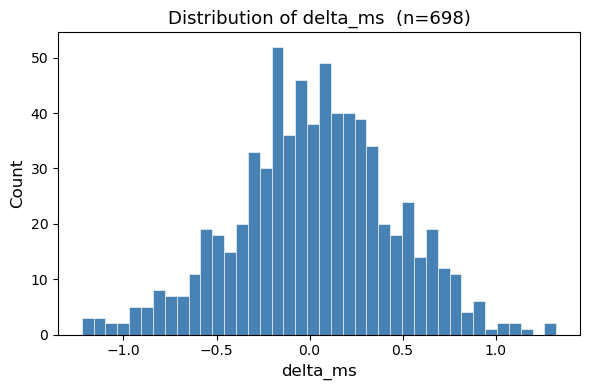

In [15]:
# Target distribution
fig, ax = plt.subplots(figsize=(6, 4))
if TASK == 'regression':
    ax.hist(y, bins=40, color='steelblue', edgecolor='white', linewidth=0.4)
    ax.set_xlabel(target, fontsize=12)
else:
    counts = df[target].value_counts()
    ax.bar(counts.index.astype(str), counts.values, color='steelblue', edgecolor='white')
    for i, v in enumerate(counts.values):
        ax.text(i, v, f'{v}', ha='center', va='bottom', fontsize=10)
    ax.set_xlabel(target, fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.set_title(f'Distribution of {target}  (n={len(y):,})', fontsize=13)
plt.tight_layout()
plt.show()

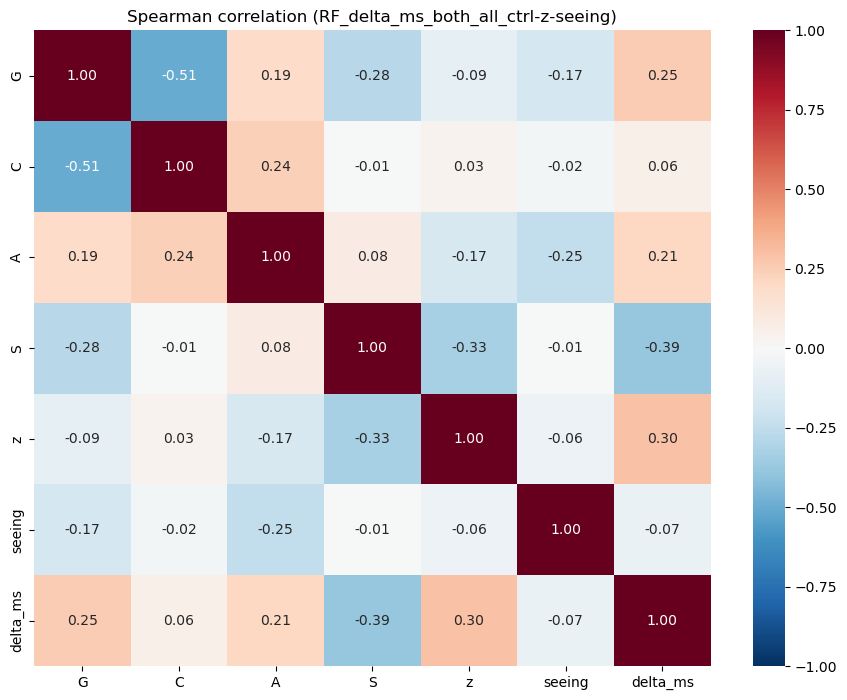

In [16]:
# Spearman correlation matrix (science features, controls, conditioning, target)
corr_df = encode(df[FULL_FEATURES])
corr_df[TARGET_LABEL] = y

corr = corr_df.corr(method='spearman')
n_corr = len(corr)
fig, ax = plt.subplots(figsize=(1.0 * n_corr + 2, 0.8 * n_corr + 1.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title(f'Spearman correlation ({RUN_LABEL})')
plt.tight_layout()
plt.show()

## Information Gain: Baseline vs GCAS vs GCAS + Baseline

Repeated stratified k-fold CV (`n_folds` x `cv_repeats`), with every model set scored on the **same splits** so the
per-split gains are paired. A linear model (Ridge / logistic regression) is fitted alongside the random forest:
if the two agree, the relationship is simple and easy to interpret; if the forest wins, it's exploiting non-linearity or interactions.

Note: the std across repeated-CV folds understates the true uncertainty (training sets overlap) —
use the permutation test below for significance.

In [17]:
def build_rf(seed_offset=0, n_estimators=None, oob_score=None):
    common = dict(
        n_estimators     = n_estimators or CONFIG['n_estimators'],
        max_features     = CONFIG['max_features'],
        max_depth        = CONFIG['max_depth'],
        min_samples_leaf = CONFIG['min_samples_leaf'],
        min_samples_split= CONFIG['min_samples_split'],
        bootstrap        = CONFIG['bootstrap'],
        oob_score        = CONFIG['oob_score'] if oob_score is None else oob_score,
        random_state     = CONFIG['random_seed'] + seed_offset,
        n_jobs           = -1,
    )
    if TASK == 'classification':
        return RandomForestClassifier(class_weight=CONFIG['class_weight'], **common)
    return RandomForestRegressor(**common)

def build_linear():
    if TASK == 'classification':
        return make_pipeline(StandardScaler(),
                             LogisticRegression(class_weight=CONFIG['class_weight'], max_iter=2000))
    return make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13)))

def predict_score(model, X):
    # Probability of the positive class for classification, prediction for regression
    return model.predict_proba(X)[:, 1] if TASK == 'classification' else model.predict(X)

def score_fn(y_true, y_pred):
    return roc_auc_score(y_true, y_pred) if TASK == 'classification' else r2_score(y_true, y_pred)

rskf = RepeatedStratifiedKFold(n_splits=CONFIG['n_folds'], n_repeats=CONFIG['cv_repeats'],
                               random_state=CONFIG['random_seed'])
splits = list(rskf.split(np.zeros(len(y)), stratify_labels))

ALGORITHMS = {
    'Random forest': lambda k: build_rf(seed_offset=k, oob_score=False),
    'Linear':        lambda k: build_linear(),
}

records = []
print(f"Running {CONFIG['n_folds']}-fold x {CONFIG['cv_repeats']} repeated CV for {len(MODEL_SETS)} model sets ...")
for split_idx, (train_idx, test_idx) in enumerate(splits):
    for set_name, feats in MODEL_SETS.items():
        Xs = X_all[feats].values
        for algo_name, builder in ALGORITHMS.items():
            model = builder(split_idx)
            model.fit(Xs[train_idx], y[train_idx])
            records.append({
                'split': split_idx, 'repeat': split_idx // CONFIG['n_folds'],
                'model_set': set_name, 'algorithm': algo_name,
                'score': score_fn(y[test_idx], predict_score(model, Xs[test_idx])),
            })
cmp_df = pd.DataFrame(records)

# Paired per-split gain from adding G/C/A/S to the baseline (vs chance if there is no baseline)
wide = cmp_df.pivot_table(index=['algorithm', 'split'], columns='model_set', values='score')
base_scores_wide = wide['Baseline'] if 'Baseline' in wide else CHANCE_SCORE
wide['gain'] = wide[FULL_SET_NAME] - base_scores_wide
gain_df = wide['gain'].reset_index()

summary = (cmp_df.groupby(['algorithm', 'model_set'])['score']
           .agg(['mean', 'std']).unstack('model_set')
           .swaplevel(axis=1).reindex(columns=list(MODEL_SETS), level=0))
gain_summary = gain_df.groupby('algorithm')['gain'].agg(['mean', 'std'])

print(f"\n=== {SCORE_NAME} by model set (mean ± std over {len(splits)} folds)  --  {RUN_LABEL} ===")
for algo in ALGORITHMS:
    row = '  '.join(f"{s}: {summary.loc[algo, (s, 'mean')]:.3f} ± {summary.loc[algo, (s, 'std')]:.3f}"
                    for s in MODEL_SETS)
    g = gain_summary.loc[algo]
    print(f"{algo:<14} {row}   |  gain from GCAS: {g['mean']:+.3f} ± {g['std']:.3f}")

Running 5-fold x 5 repeated CV for 3 model sets ...

=== R² by model set (mean ± std over 25 folds)  --  RF_delta_ms_both_all_ctrl-z-seeing ===
Random forest  Baseline: 0.067 ± 0.060  GCAS: 0.184 ± 0.075  GCAS + Baseline: 0.266 ± 0.060   |  gain from GCAS: +0.199 ± 0.070
Linear         Baseline: 0.069 ± 0.044  GCAS: 0.194 ± 0.076  GCAS + Baseline: 0.250 ± 0.079   |  gain from GCAS: +0.181 ± 0.070


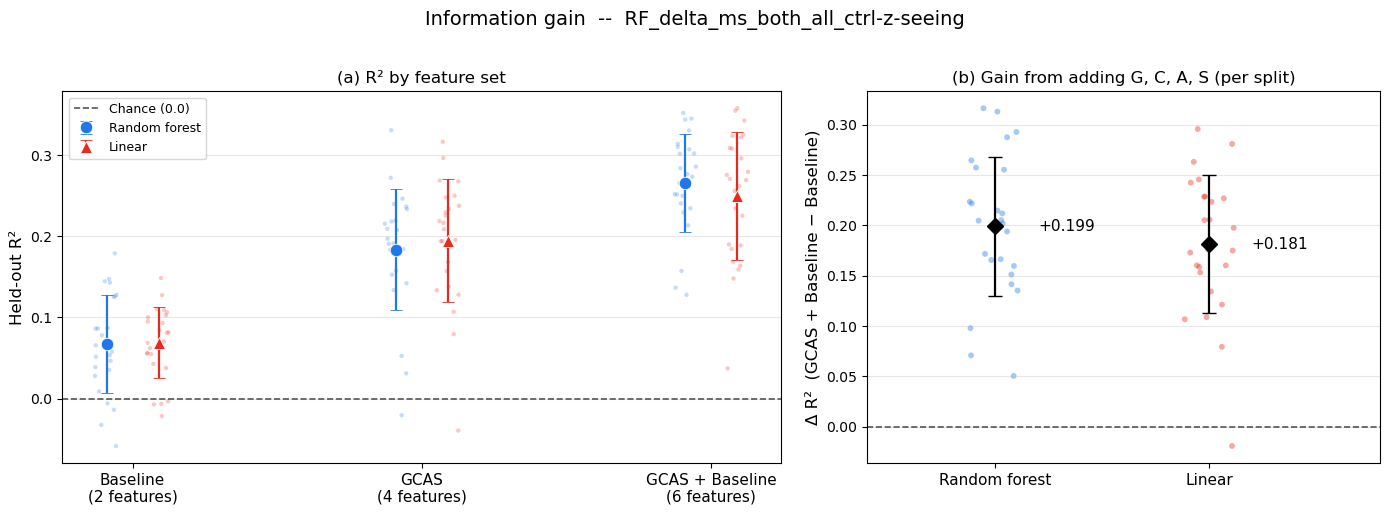

In [18]:
# ── Model-set comparison plot ─────────────────────────────────────────────────
ALGO_COLOURS = {'Random forest': '#1F77E8', 'Linear': '#E8291F'}
ALGO_MARKERS = {'Random forest': 'o', 'Linear': '^'}
set_names = list(MODEL_SETS)
x_pos = np.arange(len(set_names))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [1.4, 1]})

# (a) score per model set
for j, algo in enumerate(ALGORITHMS):
    offset = (j - 0.5) * 0.18
    means = [summary.loc[algo, (s, 'mean')] for s in set_names]
    stds  = [summary.loc[algo, (s, 'std')]  for s in set_names]
    sub = cmp_df[cmp_df['algorithm'] == algo]
    for i, s in enumerate(set_names):
        vals = sub.loc[sub['model_set'] == s, 'score'].values
        jitter = np.random.default_rng(i).uniform(-0.04, 0.04, len(vals))
        ax1.scatter(np.full(len(vals), i + offset) + jitter, vals, s=10, alpha=0.25,
                    color=ALGO_COLOURS[algo], edgecolors='none', zorder=2)
    ax1.errorbar(x_pos + offset, means, yerr=stds, fmt=ALGO_MARKERS[algo], color=ALGO_COLOURS[algo],
                 markersize=9, capsize=4, linewidth=1.6, label=algo, zorder=4,
                 markeredgecolor='white', markeredgewidth=0.6)
ax1.axhline(CHANCE_SCORE, color='#555555', linestyle='--', linewidth=1.2, label=f'Chance ({CHANCE_SCORE})')
ax1.set_xticks(x_pos)
ax1.set_xticklabels([f'{s}\n({len(MODEL_SETS[s])} features)' for s in set_names], fontsize=11)
ax1.set_ylabel(f'Held-out {SCORE_NAME}', fontsize=12)
ax1.set_title(f'(a) {SCORE_NAME} by feature set', fontsize=12)
ax1.legend(fontsize=9)
ax1.grid(axis='y', alpha=0.3)

# (b) paired per-split gain from adding G/C/A/S
for j, algo in enumerate(ALGORITHMS):
    vals = gain_df.loc[gain_df['algorithm'] == algo, 'gain'].values
    jitter = np.random.default_rng(j).uniform(-0.12, 0.12, len(vals))
    ax2.scatter(np.full(len(vals), j) + jitter, vals, s=18, alpha=0.4,
                color=ALGO_COLOURS[algo], edgecolors='none')
    ax2.errorbar(j, vals.mean(), yerr=vals.std(), fmt='D', color='black', markersize=8,
                 capsize=5, linewidth=1.6, zorder=4)
    ax2.text(j + 0.2, vals.mean(), f'{vals.mean():+.3f}', va='center', fontsize=11)
ax2.axhline(0, color='#555555', linestyle='--', linewidth=1.2)
ax2.set_xticks(range(len(ALGORITHMS)))
ax2.set_xticklabels(list(ALGORITHMS), fontsize=11)
ax2.set_xlim(-0.6, len(ALGORITHMS) - 0.2)
gain_ref = 'Baseline' if BASELINE_FEATURES else 'chance'
ax2.set_ylabel(f'Δ {SCORE_NAME}  ({FULL_SET_NAME} − {gain_ref})', fontsize=12)
ax2.set_title('(b) Gain from adding G, C, A, S (per split)', fontsize=12)
ax2.grid(axis='y', alpha=0.3)

fig.suptitle(f'Information gain  --  {RUN_LABEL}', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# if CONFIG['save_outputs']:
#     cmp_df.to_csv(os.path.join(CONFIG['output_dir'], f'{RUN_LABEL}_model_set_scores.csv'), index=False)
#     out = summary.copy()
#     out.columns = [f'{s}_{stat}' for s, stat in out.columns]
#     out = out.join(gain_summary.add_prefix('gain_'))
#     out.to_csv(os.path.join(CONFIG['output_dir'], f'{RUN_LABEL}_model_set_summary.csv'))
#     print(f"Saved model-set scores and summary to {CONFIG['output_dir']}/")

### Permutation test of the GCAS gain

Shuffle G, C, A, S **jointly** (rows of the whole block, so their mutual correlations are kept) while leaving the
controls and target untouched, refit, and recompute the gain. Repeating this builds the null distribution of the gain
when morphology carries no information about the target. p = (1 + #{null ≥ observed}) / (1 + n_perm).
Uses the first repeat's folds and `perm_test_n_estimators` trees for speed.

  20/100 permutations done
  40/100 permutations done
  60/100 permutations done
  80/100 permutations done
  100/100 permutations done

Observed gain (200 trees, 5 folds): +0.1976
Null gain: mean +0.0126, 95th pct +0.0336
Permutation p-value: 0.0099  (at the resolution limit — increase n_perm_test for a smaller p)


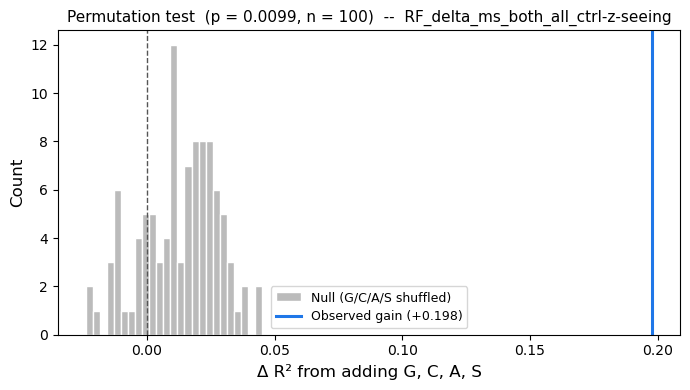

In [19]:
if CONFIG['n_perm_test'] > 0:
    test_splits = splits[:CONFIG['n_folds']]
    n_est = CONFIG['perm_test_n_estimators']
    full_feats = MODEL_SETS[FULL_SET_NAME]
    X_full_arr = X_all[full_feats].values
    sci_idx = [full_feats.index(f) for f in SCIENCE_FEATURES]

    def cv_fold_scores(X_arr):
        scores = []
        for k, (tr, te) in enumerate(test_splits):
            model = build_rf(seed_offset=k, n_estimators=n_est, oob_score=False)
            model.fit(X_arr[tr], y[tr])
            scores.append(score_fn(y[te], predict_score(model, X_arr[te])))
        return np.array(scores)

    # The baseline doesn't change under permutation, so score it once
    if BASELINE_FEATURES:
        perm_base_scores = cv_fold_scores(X_all[BASELINE_FEATURES].values)
    else:
        perm_base_scores = np.full(len(test_splits), CHANCE_SCORE)

    observed_gain = (cv_fold_scores(X_full_arr) - perm_base_scores).mean()

    rng_perm = np.random.default_rng(CONFIG['random_seed'] + 1)
    null_gains = np.empty(CONFIG['n_perm_test'])
    for i in range(CONFIG['n_perm_test']):
        X_perm = X_full_arr.copy()
        X_perm[:, sci_idx] = X_full_arr[rng_perm.permutation(len(y))][:, sci_idx]
        null_gains[i] = (cv_fold_scores(X_perm) - perm_base_scores).mean()
        if (i + 1) % 20 == 0:
            print(f"  {i + 1}/{CONFIG['n_perm_test']} permutations done")

    p_value = (1 + np.sum(null_gains >= observed_gain)) / (1 + CONFIG['n_perm_test'])
    print(f"\nObserved gain ({n_est} trees, {len(test_splits)} folds): {observed_gain:+.4f}")
    print(f"Null gain: mean {null_gains.mean():+.4f}, 95th pct {np.percentile(null_gains, 95):+.4f}")
    print(f"Permutation p-value: {p_value:.4f}"
          + ("  (at the resolution limit — increase n_perm_test for a smaller p)"
             if p_value == 1 / (1 + CONFIG['n_perm_test']) else ''))

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(null_gains, bins=25, color='#BBBBBB', edgecolor='white', label='Null (G/C/A/S shuffled)')
    ax.axvline(observed_gain, color='#1F77E8', linewidth=2.2, label=f'Observed gain ({observed_gain:+.3f})')
    ax.axvline(0, color='#555555', linestyle='--', linewidth=1)
    ax.set_xlabel(f'Δ {SCORE_NAME} from adding G, C, A, S', fontsize=12)
    ax.set_ylabel('Count', fontsize=12)
    ax.set_title(f'Permutation test  (p = {p_value:.3g}, n = {CONFIG["n_perm_test"]})  --  {RUN_LABEL}', fontsize=11)
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.show()

    if CONFIG['save_outputs']:
        pd.DataFrame({'null_gain': null_gains}).assign(observed_gain=observed_gain, p_value=p_value).to_csv(
            os.path.join(CONFIG['output_dir'], f'{RUN_LABEL}_perm_test.csv'), index=False)
else:
    print("Permutation test skipped (n_perm_test = 0)")

## Full Model: 5-Fold Stratified Cross Validation Loop

Everything from here on uses the **GCAS + Baseline** feature set (plus the RANDOM noise feature),
single k-fold CV, so each galaxy gets exactly one out-of-fold prediction.

In [20]:
# ── Features for the detailed model ──────────────────────────────────────────
FEATURES = MODEL_SETS[FULL_SET_NAME] + ['RANDOM']
X = X_all[FEATURES].values
feature_names = FEATURES

# ── Initialise storage ───────────────────────────────────────────────────────
fold_metrics = []
fold_rocs = []
mdi_importances  = []
perm_importances = []
oof_true = y.copy()
oof_pred = np.zeros(len(y))

# ── Cross Validation splitter (stratified) ───────────────────────────────────
skf = StratifiedKFold(
    n_splits=CONFIG['n_folds'],
    shuffle=True,
    random_state=CONFIG['random_seed'],
)

# ── Main CV loop ─────────────────────────────────────────────────────────────
print(f"Running {CONFIG['n_folds']}-fold stratified CV  --  {RUN_LABEL}")
print(f"Features ({len(feature_names)}): {feature_names}")
metric_names = ['R2', 'RMSE', 'MAE', 'OOB_R2'] if TASK == 'regression' else ['AUC', 'Accuracy', 'Bal_acc', 'OOB_acc']
print(f"{'Fold':>5}  {'N_train':>8}  {'N_test':>7}  " + '  '.join(f'{m:>8}' for m in metric_names))
print("-" * 65)

for fold_idx, (train_idx, test_idx) in enumerate(skf.split(X, stratify_labels)):

    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    rf = build_rf(seed_offset=fold_idx)
    rf.fit(X_train, y_train)
    y_pred = predict_score(rf, X_test)
    oof_pred[test_idx] = y_pred
    oob = getattr(rf, 'oob_score_', np.nan)

    if TASK == 'regression':
        m = {'R2':   r2_score(y_test, y_pred),
             'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
             'MAE':  mean_absolute_error(y_test, y_pred),
             'OOB_R2': oob}
    else:
        y_class = (y_pred >= 0.5).astype(int)
        m = {'AUC':      roc_auc_score(y_test, y_pred),
             'Accuracy': accuracy_score(y_test, y_class),
             'Bal_acc':  balanced_accuracy_score(y_test, y_class),
             'OOB_acc':  oob}
        fold_rocs.append(roc_curve(y_test, y_pred)[:2])
    fold_metrics.append(m)

    # MDI importance (in-sample)
    mdi_importances.append(rf.feature_importances_)

    # Permutation importance (out-of-sample, on held-out fold) — PRIMARY
    perm_result = permutation_importance(
        rf, X_test, y_test,
        n_repeats   = CONFIG['perm_n_repeats'],
        random_state= CONFIG['random_seed'] + fold_idx,
        n_jobs      = -1,
        scoring     = SCORING,
    )
    perm_importances.append(perm_result.importances_mean)

    print(f"{fold_idx+1:>5}  {len(y_train):>8,}  {len(y_test):>7,}  " + '  '.join(f'{m[k]:>8.4f}' for k in metric_names))

fold_df = pd.DataFrame(fold_metrics)
print("-" * 65)
print(f"{'Mean':>5}  {'':>8}  {'':>7}  " + '  '.join(f'{v:>8.4f}' for v in fold_df.mean()))
print(f"{'Std':>5}  {'':>8}  {'':>7}  " + '  '.join(f'{v:>8.4f}' for v in fold_df.std(ddof=0)))

Running 5-fold stratified CV  --  RF_delta_ms_both_all_ctrl-z-seeing
Features (7): ['G', 'C', 'A', 'S', 'z', 'seeing', 'RANDOM']
 Fold   N_train   N_test        R2      RMSE       MAE    OOB_R2
-----------------------------------------------------------------
    1       558      140    0.2655    0.3311    0.2631    0.2675
    2       558      140    0.2844    0.3316    0.2556    0.2519
    3       558      140    0.2672    0.4235    0.3282    0.2655
    4       559      139    0.1288    0.3615    0.2710    0.2951
    5       559      139    0.2696    0.3801    0.2925    0.2642
-----------------------------------------------------------------
 Mean                       0.2431    0.3656    0.2821    0.2688
  Std                       0.0576    0.0344    0.0262    0.0142


## Performance Summary and Predicted vs Actual Plot

=== Performance Summary  --  RF_delta_ms_both_all_ctrl-z-seeing ===
Metric   Mean    Std    Min    Max
    R2 0.2431 0.0576 0.1288 0.2844
  RMSE 0.3656 0.0344 0.3311 0.4235
   MAE 0.2821 0.0262 0.2556 0.3282
OOB_R2 0.2688 0.0142 0.2519 0.2951


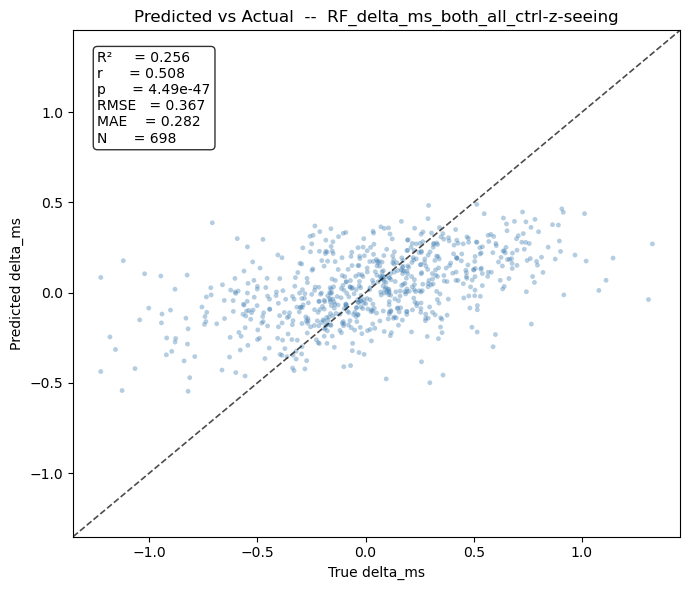

In [21]:
# Performance summary table
perf_df = pd.DataFrame({
    'Metric': fold_df.columns,
    'Mean':   fold_df.mean().values,
    'Std':    fold_df.std(ddof=0).values,
    'Min':    fold_df.min().values,
    'Max':    fold_df.max().values,
})
print(f"=== Performance Summary  --  {RUN_LABEL} ===")
print(perf_df.to_string(index=False, float_format='{:.4f}'.format))

if TASK == 'regression':
    # Predicted vs Actual scatter (out-of-fold — full sample, no leakage)
    overall_r2   = r2_score(oof_true, oof_pred)
    overall_rmse = np.sqrt(mean_squared_error(oof_true, oof_pred))
    overall_mae  = mean_absolute_error(oof_true, oof_pred)
    r_pearson, p_pearson = pearsonr(oof_true, oof_pred)

    fig, ax = plt.subplots(figsize=(7, 6))
    ax.scatter(oof_true, oof_pred, s=12, alpha=0.4, color='steelblue',
               edgecolors='none', rasterized=True)
    lo = min(oof_true.min(), oof_pred.min())
    hi = max(oof_true.max(), oof_pred.max())
    pad = 0.05 * (hi - lo)
    lims = [lo - pad, hi + pad]
    ax.plot(lims, lims, 'k--', linewidth=1.2, alpha=0.7)
    ax.set_xlim(lims); ax.set_ylim(lims)
    textstr = (f'R²     = {overall_r2:.3f}\n'
               f'r      = {r_pearson:.3f}\n'
               f'p      = {p_pearson:.2e}\n'
               f'RMSE   = {overall_rmse:.3f}\n'
               f'MAE    = {overall_mae:.3f}\n'
               f'N      = {len(oof_true):,}')
    ax.text(0.04, 0.96, textstr, transform=ax.transAxes, fontsize=10,
            verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    ax.set_xlabel(f'True {target}'); ax.set_ylabel(f'Predicted {target}')
    ax.set_title(f'Predicted vs Actual  --  {RUN_LABEL}')
    plt.tight_layout()
    plt.show()

else:
    # ROC curve, confusion matrix and predicted-probability distributions (out-of-fold)
    overall_auc = roc_auc_score(oof_true, oof_pred)
    oof_class = (oof_pred >= 0.5).astype(int)
    class_names = [f'not {POSITIVE_CLASS}', POSITIVE_CLASS]
    other_classes = [c for c in df[target].unique() if c != POSITIVE_CLASS]
    if len(other_classes) == 1:
        class_names[0] = other_classes[0]

    fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

    ax = axes[0]
    for fpr, tpr in fold_rocs:
        ax.plot(fpr, tpr, color='steelblue', alpha=0.25, linewidth=1)
    fpr, tpr, _ = roc_curve(oof_true, oof_pred)
    ax.plot(fpr, tpr, color='#1F77E8', linewidth=2.2, label=f'Out-of-fold (AUC = {overall_auc:.3f})')
    ax.plot([0, 1], [0, 1], 'k--', linewidth=1.2, alpha=0.7, label='Chance')
    ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate')
    ax.set_title('(a) ROC curve (faint = individual folds)')
    ax.legend(fontsize=9, loc='lower right')

    ax = axes[1]
    cm = confusion_matrix(oof_true, oof_class)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    annot = np.array([[f'{cm[i, j]}\n({cm_norm[i, j]:.0%})' for j in range(2)] for i in range(2)])
    sns.heatmap(cm_norm, annot=annot, fmt='', cmap='Blues', vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=class_names, yticklabels=class_names, annot_kws={'fontsize': 12})
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.set_title(f'(b) Confusion matrix (threshold 0.5)\nbalanced acc = {balanced_accuracy_score(oof_true, oof_class):.3f}')

    ax = axes[2]
    bins = np.linspace(0, 1, 26)
    for cls, name, colour in [(0, class_names[0], '#1F77E8'), (1, class_names[1], '#E8291F')]:
        ax.hist(oof_pred[oof_true == cls], bins=bins, alpha=0.55, color=colour, density=True,
                edgecolor='white', linewidth=0.4, label=f'True {name} (n={np.sum(oof_true == cls)})')
    ax.axvline(0.5, color='#555555', linestyle='--', linewidth=1.2)
    ax.set_xlabel(f'Predicted P({POSITIVE_CLASS})'); ax.set_ylabel('Density')
    ax.set_title('(c) Out-of-fold predicted probabilities')
    ax.legend(fontsize=9)

    fig.suptitle(f'Classification performance  --  {RUN_LABEL}', fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

In [22]:
# # Save performance summary
# if CONFIG['save_outputs']:
#     perf_out_path = os.path.join(CONFIG['output_dir'], f'{RUN_LABEL}_performance.csv')
#     perf_df.to_csv(perf_out_path, index=False)
#     print(f"Saved {perf_out_path}")

## Feature Importance: Permutation (Primary) and MDI (Secondary)

Hatched bars are controls / conditioning variables: they are in the model to absorb observational or physical
effects, so their importance is not interpreted as a result.

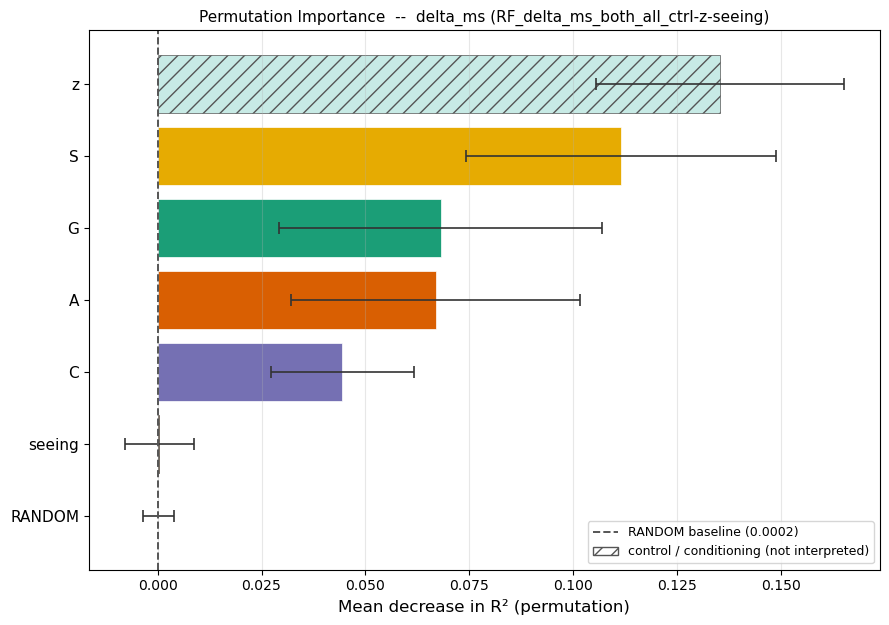

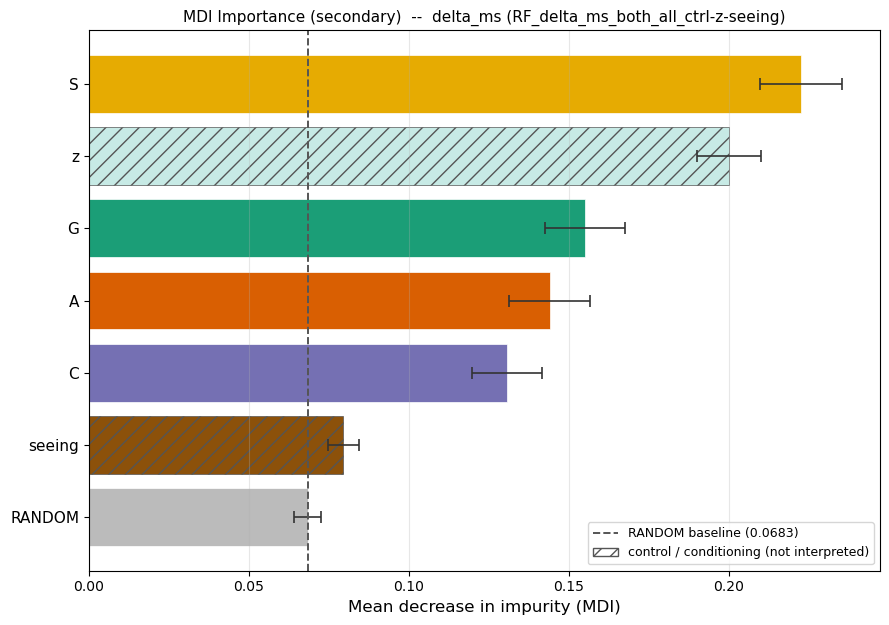

In [23]:
# Aggregate importances across folds
mdi_array  = np.array(mdi_importances)
perm_array = np.array(perm_importances)

perm_df = pd.DataFrame({
    'Feature': feature_names, 'Perm_Mean': perm_array.mean(axis=0),
    'Perm_Std': perm_array.std(axis=0),
}).sort_values('Perm_Mean', ascending=False).reset_index(drop=True)

mdi_df = pd.DataFrame({
    'Feature': feature_names, 'MDI_Mean': mdi_array.mean(axis=0),
    'MDI_Std': mdi_array.std(axis=0),
}).sort_values('MDI_Mean', ascending=False).reset_index(drop=True)

random_perm = perm_df.loc[perm_df['Feature'] == 'RANDOM', 'Perm_Mean'].values[0]
random_mdi  = mdi_df.loc[mdi_df['Feature']  == 'RANDOM', 'MDI_Mean'].values[0]

# Feature colour map — add new features, keep existing colours consistent
FEATURE_COLOURS = {
    # science features
    'G':                      '#1B9E77',  # teal-green  -- Gini
    'C':                      '#7570B3',  # slate       -- Concentration
    'A':                      '#D95F02',  # burnt orange-- Asymmetry
    'S':                      '#E6AB02',  # mustard     -- Smoothness/clumpiness
    # controls
    'z':                      '#C7EAE5',  # pale teal   -- redshift
    'seeing':                 '#8C510A',  # brown       -- PSF / seeing
    'n_res':                  '#01665E',  # dark teal   -- resolution elements
    'ellip':                  '#4D9221',  # dark green  -- structural / inclination
    # physical (targets or conditioning)
    'log_Mstar':              '#2166AC',  # dark blue   -- stellar mass
    'log_sSFR':               '#4DAC26',  # green       -- SF activity
    'log_SFR':                '#B8E186',  # light green -- SFR
    'delta_ms':               '#9B30D9',  # purple      -- SFMS offset
    '5NN':                    '#D6604D',  # red         -- local density
    'environment':            '#F4A582',  # light red   -- broad environment
    'spectral_class':         '#E08214',  # orange      -- SF class
    're':                     '#35978F',  # teal        -- galaxy size
    're_kpc':                 '#80CDC1',  # light teal  -- physical size
    'RANDOM':                 '#BBBBBB',  # grey        -- noise baseline
}

def importance_bar_chart(df_imp, mean_col, std_col, random_val, title, xlabel, filename):
    n = len(df_imp)
    fig, ax = plt.subplots(figsize=(9, 0.65 * n + 1.8))
    features = df_imp['Feature'].tolist()
    means, stds = df_imp[mean_col].values, df_imp[std_col].values
    colours = [FEATURE_COLOURS.get(f, '#888888') for f in features]
    y_pos = np.arange(n)[::-1]
    bars = ax.barh(y_pos, means, xerr=stds, capsize=4, color=colours,
                   edgecolor='white', linewidth=0.5,
                   error_kw={'elinewidth': 1.2, 'ecolor': '#333333', 'capthick': 1.2})
    for bar, f in zip(bars, features):
        if f in BASELINE_FEATURES:
            bar.set_hatch('//')
            bar.set_edgecolor('#555555')
    ax.axvline(random_val, color='#555555', linestyle='--', linewidth=1.4,
               label=f'RANDOM baseline ({random_val:.4f})')
    handles, labels = ax.get_legend_handles_labels()
    if BASELINE_FEATURES:
        handles.append(Patch(facecolor='white', edgecolor='#555555', hatch='//'))
        labels.append('control / conditioning (not interpreted)')
    ax.set_yticks(y_pos); ax.set_yticklabels(features, fontsize=11)
    ax.set_xlabel(xlabel, fontsize=12); ax.set_title(title, fontsize=11)
    ax.legend(handles, labels, fontsize=9); ax.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()

importance_bar_chart(perm_df, 'Perm_Mean', 'Perm_Std', random_perm,
    title=f'Permutation Importance  --  {TARGET_LABEL} ({RUN_LABEL})',
    xlabel=f'Mean decrease in {SCORE_NAME} (permutation)',
    filename='perm_importance')

importance_bar_chart(mdi_df, 'MDI_Mean', 'MDI_Std', random_mdi,
    title=f'MDI Importance (secondary)  --  {TARGET_LABEL} ({RUN_LABEL})',
    xlabel='Mean decrease in impurity (MDI)',
    filename='mdi_importance')

In [24]:
# # Save importance numbers
# if CONFIG['save_outputs']:
#     importance_out = perm_df.merge(mdi_df, on='Feature')
#     importance_out['Role'] = importance_out['Feature'].map(
#         lambda f: 'science' if f in SCIENCE_FEATURES else
#                   'control' if f in CONTROL_FEATURES else
#                   'conditioning' if f in CONDITION_FEATURES else 'noise')
#     imp_out_path = os.path.join(CONFIG['output_dir'], f'{RUN_LABEL}_importance.csv')
#     importance_out.to_csv(imp_out_path, index=False)
#     print(f"Saved {imp_out_path}")

## Save to Shared Importances Folder

For the continuous thesis targets (`delta_ms`, `log_sSFR`, `log_SFR`, `log_Mstar`) this writes
`importances/{ALGO_TAG}_morph_{target}.csv` and `..._performance.csv`, overwriting the previous run of that target.
The run's config (controls, condition_on, N) is stored in both files so the thesis figure can refuse to mix configs.

In [25]:
ALGO_TAG = 'RF'   # prefix in importances/ and thesis_figures/ — change in the other algorithms' notebooks
THESIS_TARGETS = ['delta_ms', 'log_sSFR', 'log_SFR', 'log_Mstar']

if not CONFIG['save_importances']:
    print("save_importances is False — nothing written")
elif target not in THESIS_TARGETS:
    print(f"'{target}' is not one of the thesis figure targets {THESIS_TARGETS} — nothing written")
else:
    run_meta = {
        'controls':     '|'.join(CONTROL_FEATURES),
        'condition_on': '|'.join(CONDITION_FEATURES),
        'n_galaxies':   len(y),
        'run_label':    RUN_LABEL,
    }

    # Importances of the full (GCAS + Baseline) model, with each feature's role
    imp_shared = perm_df.merge(mdi_df, on='Feature')
    imp_shared['Role'] = imp_shared['Feature'].map(
        lambda f: 'science' if f in SCIENCE_FEATURES else
                  'control' if f in CONTROL_FEATURES else
                  'conditioning' if f in CONDITION_FEATURES else 'noise')

    # Performance: single k-fold metrics of the full model, plus the repeated-CV
    # model-set scores and the headline gain from adding G, C, A, S (random forest)
    rf_cmp = cmp_df[cmp_df['algorithm'] == 'Random forest']
    extra_rows = []
    for set_name, label in [('Baseline', 'Baseline_R2'), ('GCAS', 'GCAS_R2'), ('GCAS + Baseline', 'Full_R2')]:
        if set_name in MODEL_SETS:
            v = rf_cmp.loc[rf_cmp['model_set'] == set_name, 'score']
            extra_rows.append({'Metric': label, 'Mean': v.mean(), 'Std': v.std(), 'Min': v.min(), 'Max': v.max()})
    g = gain_df.loc[gain_df['algorithm'] == 'Random forest', 'gain']
    extra_rows.append({'Metric': 'Gain_GCAS', 'Mean': g.mean(), 'Std': g.std(), 'Min': g.min(), 'Max': g.max()})
    if CONFIG['n_perm_test'] > 0:
        extra_rows.append({'Metric': 'Gain_GCAS_perm_p', 'Mean': p_value, 'Std': np.nan, 'Min': np.nan, 'Max': np.nan})
    perf_shared = pd.concat([perf_df, pd.DataFrame(extra_rows)], ignore_index=True)

    for k, v in run_meta.items():
        imp_shared[k] = v
        perf_shared[k] = v

    os.makedirs(CONFIG['importances_dir'], exist_ok=True)
    stem = os.path.join(CONFIG['importances_dir'], f'{ALGO_TAG}_morph_{target}')
    imp_shared.to_csv(f'{stem}.csv', index=False)
    perf_shared.to_csv(f'{stem}_performance.csv', index=False)
    print(f"Saved {stem}.csv and {stem}_performance.csv  (config: {RUN_LABEL})")

Saved ../../importances/RF_morph_delta_ms.csv and ../../importances/RF_morph_delta_ms_performance.csv  (config: RF_delta_ms_both_all_ctrl-z-seeing)


## Feature Relationship Explorer

Target vs each feature, with binned trends. For classification the y-axis is the class indicator (jittered)
and the binned points are the fraction of the positive class.

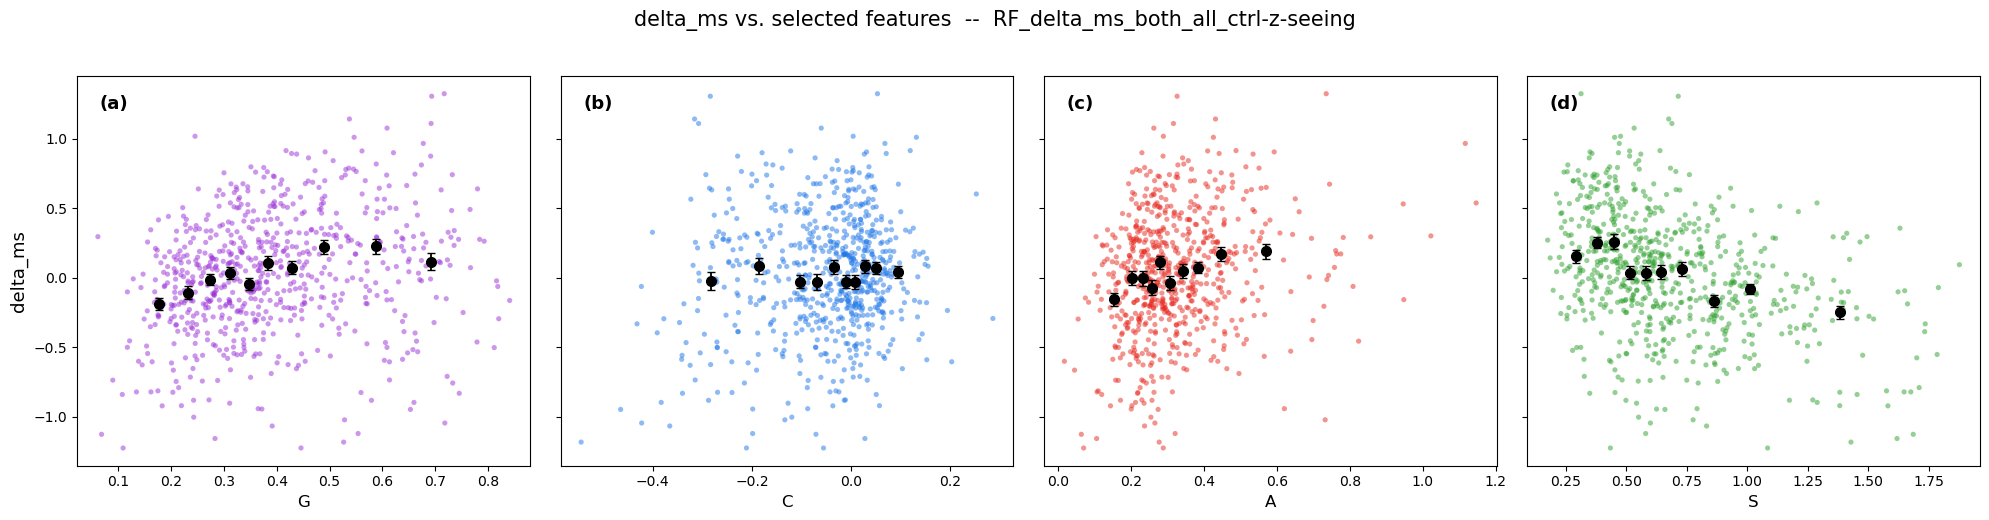

In [26]:
FEATURES_TO_PLOT = SCIENCE_FEATURES.copy()   # any columns of df; e.g. ['G', 'S', 'z', 'log_Mstar']

N_BINS = 10
PANEL_COLOURS = ['#9B30D9', '#1F77E8', '#E8291F', '#2CA02C', '#E08214', '#35978F']
PANEL_LETTERS = [f'({chr(97 + i)})' for i in range(len(FEATURES_TO_PLOT))]

for f in FEATURES_TO_PLOT:
    assert f in df.columns, f"'{f}' not found in df — check spelling"

def binned_trend(x, vals, n_bins=N_BINS, stat=np.mean):
    # Quantile bins in x; returns bin centre, statistic of vals, and standard error
    ok = np.isfinite(x) & np.isfinite(vals)
    x, vals = x[ok], vals[ok]
    bin_edges = np.unique(np.nanquantile(x, np.linspace(0, 1, n_bins + 1)))
    bin_idx = np.digitize(x, bin_edges[1:-1])
    bx, by, byerr = [], [], []
    for b in range(len(bin_edges) - 1):
        mask = bin_idx == b
        if mask.sum() < 3:
            continue
        bx.append(stat(x[mask]))
        by.append(stat(vals[mask]))
        byerr.append(np.std(vals[mask]) / np.sqrt(mask.sum()))
    return np.array(bx), np.array(by), np.array(byerr)

n_panels = len(FEATURES_TO_PLOT)
fig, axes = plt.subplots(1, n_panels, figsize=(5 * n_panels, 5), sharey=True, squeeze=False)
axes = axes[0]
target_vals = y.astype(float)
jitter = np.random.default_rng(0).uniform(-0.05, 0.05, len(y)) if TASK == 'classification' else 0

for i, (ax, feat) in enumerate(zip(axes, FEATURES_TO_PLOT)):
    colour = PANEL_COLOURS[i % len(PANEL_COLOURS)]
    is_binary = df[feat].nunique() <= 2

    if is_binary:
        if TASK == 'regression':
            sns.boxplot(
                x=df[feat].values, y=target_vals, ax=ax,
                color=colour, width=0.5, fliersize=2,
                boxprops=dict(alpha=0.75), medianprops=dict(color='black', linewidth=1.5),
            )
        else:
            sns.barplot(x=df[feat].values, y=target_vals, ax=ax, color=colour, alpha=0.75)

    else:
        x = df[feat].values.astype(float)
        ax.scatter(x, target_vals + jitter, s=14, alpha=0.5 if TASK == 'regression' else 0.25,
                   color=colour, edgecolors='none', rasterized=True)

        # Binned medians (regression) or binned class fraction (classification)
        stat = np.median if TASK == 'regression' else np.mean
        bin_x, bin_y, bin_yerr = binned_trend(x, target_vals, stat=stat)
        ax.errorbar(bin_x, bin_y, yerr=bin_yerr, fmt='o', color='black',
                    markerfacecolor='black', markersize=7, linewidth=1.3,
                    capsize=3, zorder=5)

    # Panel letter, top-left
    ax.text(0.05, 0.95, PANEL_LETTERS[i], transform=ax.transAxes,
            fontsize=13, fontweight='bold', va='top', ha='left')

    ax.set_xlabel(feat, fontsize=12)
    if i == 0:
        ax.set_ylabel(target if TASK == 'regression' else f'Fraction {POSITIVE_CLASS}', fontsize=13)

fig.suptitle(f'{TARGET_LABEL} vs. selected features  --  {RUN_LABEL}', fontsize=15, y=1.03)
plt.tight_layout()
plt.show()

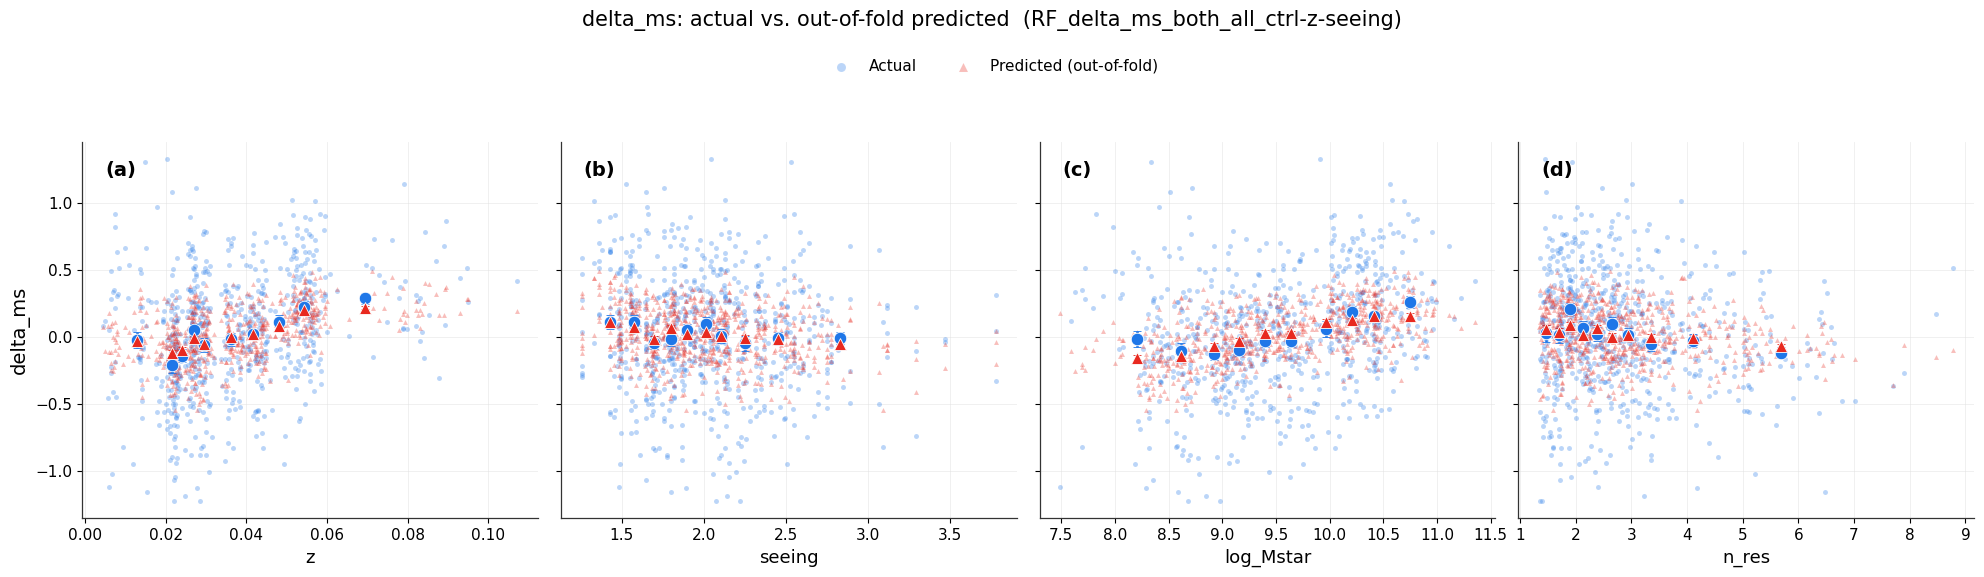

In [27]:
## ── Actual vs. Predicted vs. Feature (out-of-fold, full k-fold CV) — thesis-ready ──
# Useful for checking whether the model's success/failure tracks observing conditions
# (z, seeing, n_res) or physical properties not in the model.

FEATURES_TO_PLOT = ['z', 'seeing', 'log_Mstar', 'n_res']   # any columns of df
PANEL_LETTERS = [f'({chr(97 + i)})' for i in range(len(FEATURES_TO_PLOT))]
N_BINS = 10

# Colourblind-safe, higher-contrast pair
CATEGORY_COLOURS = {
    'Actual':    '#1F77E8',  # deep blue
    'Predicted': '#E8291F',  # vermillion
}

for f in FEATURES_TO_PLOT:
    assert f in df.columns, f"'{f}' not found in df — check spelling"

actual_label = 'Actual' if TASK == 'regression' else f'Actual fraction {POSITIVE_CLASS}'
pred_label = 'Predicted (out-of-fold)' if TASK == 'regression' else 'Predicted probability (out-of-fold)'

with plt.rc_context({
    'font.size': 12,
    'axes.labelsize': 13,
    'axes.titlesize': 13,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.edgecolor': '#333333',
    'axes.linewidth': 0.9,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'grid.color': '#dddddd',
    'grid.linewidth': 0.6,
}):
    n_panels = len(FEATURES_TO_PLOT)
    fig, axes = plt.subplots(1, n_panels, figsize=(5 * n_panels, 5), sharey=True, squeeze=False)
    axes = axes[0]

    for i, (ax, feat) in enumerate(zip(axes, FEATURES_TO_PLOT)):
        x = df[feat].values.astype(float)

        # Scatter — small, low alpha, thin white edge to keep it crisp rather than muddy
        # (classification: only predicted probabilities are scattered; the 0/1 truth is shown binned)
        if TASK == 'regression':
            ax.scatter(x, oof_true, s=13, alpha=0.30, color=CATEGORY_COLOURS['Actual'],
                       edgecolors='white', linewidths=0.15, label=actual_label, rasterized=True, zorder=2)
        ax.scatter(x, oof_pred, s=13, alpha=0.30, marker='^', color=CATEGORY_COLOURS['Predicted'],
                   edgecolors='white', linewidths=0.15, label=pred_label,
                   rasterized=True, zorder=2)

        # Binned trend lines — this is what actually sells the story
        bx, by_true, byerr_true = binned_trend(x, oof_true.astype(float))
        bx_p, by_pred, byerr_pred = binned_trend(x, oof_pred)
        ax.errorbar(bx, by_true, yerr=byerr_true, fmt='o', color=CATEGORY_COLOURS['Actual'],
                    markersize=9, linewidth=1.8, capsize=3, zorder=4,
                    markeredgecolor='white', markeredgewidth=0.6,
                    label=None if TASK == 'regression' else actual_label)
        ax.errorbar(bx_p, by_pred, yerr=byerr_pred, fmt='^', color=CATEGORY_COLOURS['Predicted'],
                    markersize=9, linewidth=1.8, capsize=3, zorder=4,
                    markeredgecolor='white', markeredgewidth=0.6)

        ax.text(0.05, 0.95, PANEL_LETTERS[i], transform=ax.transAxes,
                fontsize=14, fontweight='bold', va='top', ha='left')
        ax.set_xlabel(feat, fontsize=13)
        if i == 0:
            ax.set_ylabel(target if TASK == 'regression' else f'P({POSITIVE_CLASS})', fontsize=14)
        ax.grid(alpha=0.5, zorder=0)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles[:2], labels[:2], loc='upper center', bbox_to_anchor=(0.5, 1.08),
               ncol=2, fontsize=11, frameon=False, markerscale=1.8)
    fig.suptitle(f'{TARGET_LABEL}: actual vs. out-of-fold predicted  ({RUN_LABEL})',
                 fontsize=15, y=1.15)
    plt.tight_layout()
    plt.show()

## Prediction Precision in dex

How precisely can the target be predicted, in its own units (dex for `delta_ms`, `log_sSFR`, `log_SFR`, `log_Mstar`)?
R² says *how much* of the variance is explained; this section turns that into "predicted to within X dex".

**How it works.** The repeated CV above (same splits) is refitted, keeping every galaxy's **out-of-fold** prediction
in each repeat — a prediction from a model that never saw that galaxy. Residuals (predicted − true) give:

| Metric | Meaning |
|---|---|
| **RMSE** | root-mean-square error; for *No information* this is just the target's RMS scatter (e.g. RMS ΔMS) |
| **MAE** | mean absolute error; for *No information* this is the target's mean absolute deviation about its median |
| **NMAD** | 1.4826 × median absolute deviation of the residuals — Gaussian-equivalent scatter that ignores outliers |
| **Within 0.2 / 0.3 dex** | fraction of galaxies predicted that closely |
| **Spearman ρ** | does the model at least *rank* galaxies correctly? |
| **Correct side of MS** | (`delta_ms` only) fraction where predicted and true ΔMS have the same sign |
| **Scatter reduction** | 1 − RMSE / RMSE(No information): the fraction of the target's scatter removed |

**No information** predicts the training-fold median for every galaxy, so its errors *are* the target's intrinsic
scatter in this sample — the reference every model is compared against. Each metric is averaged over the CV repeats;
the ± is a 1σ bootstrap over galaxies, resampled identically for every model set so the differences are paired.

The right-hand panel shows *where* the precision comes from: tree models pull predictions towards the mean,
so galaxies far from the typical value (e.g. starbursts or galaxies falling off the main sequence) are usually
predicted worst.

Refitting 3 model sets on 25 folds for out-of-fold predictions ...

=== Prediction precision (dex), out-of-fold, 5 CV repeats, 1000 bootstraps  --  RF_delta_ms_both_all_ctrl-z-seeing ===
                       No information       Baseline            GCAS GCAS + Baseline
RMSE                    0.426 ± 0.012  0.409 ± 0.012   0.382 ± 0.011   0.362 ± 0.011
MAE                     0.335 ± 0.010  0.318 ± 0.010   0.297 ± 0.009   0.279 ± 0.009
NMAD                    0.391 ± 0.018  0.376 ± 0.015   0.360 ± 0.016   0.331 ± 0.016
Bias                    0.008 ± 0.016  0.001 ± 0.016  -0.000 ± 0.014   0.001 ± 0.014
Within_0.2dex           0.385 ± 0.018  0.399 ± 0.017   0.429 ± 0.017   0.458 ± 0.018
Within_0.3dex           0.555 ± 0.019  0.573 ± 0.018   0.595 ± 0.017   0.625 ± 0.017
Spearman_rho                        —  0.276 ± 0.034   0.439 ± 0.031   0.527 ± 0.028
Correct_side_of_MS      0.529 ± 0.019  0.567 ± 0.015   0.652 ± 0.016   0.707 ± 0.015
Scatter_reduction_RMSE  0.000 ± 0.000  0.040 ± 0

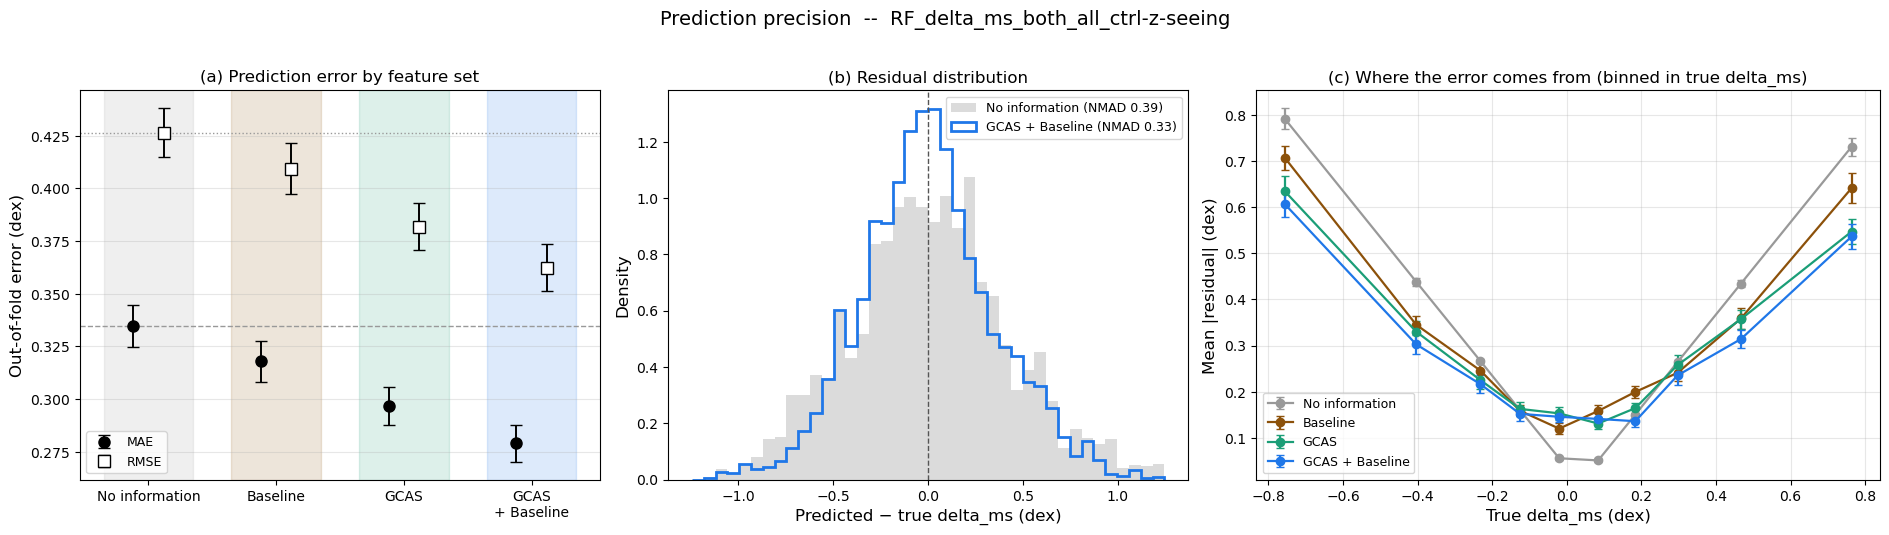

Saved ../../importances/RF_morph_delta_ms_precision.csv


In [29]:
## ── Prediction precision in dex (continuous targets only) ──
PRECISION_N_BOOT = 1000

if TASK != 'regression':
    print("Precision in dex only applies to continuous targets — skipped")
else:
    from scipy.stats import spearmanr

    UNIT = 'dex' if (target.startswith('log_') or target == 'delta_ms') else f'{target} units'
    NULL_NAME = 'No information'
    PREC_SETS = {NULL_NAME: None, **MODEL_SETS}
    n_rep = CONFIG['cv_repeats']

    # ── Out-of-fold predictions for every CV repeat (same splits and seeds as the information-gain section) ──
    oof_rep = {name: np.zeros((n_rep, len(y))) for name in PREC_SETS}
    print(f"Refitting {len(MODEL_SETS)} model sets on {len(splits)} folds for out-of-fold predictions ...")
    for split_idx, (train_idx, test_idx) in enumerate(splits):
        rep = split_idx // CONFIG['n_folds']
        for name, feats in PREC_SETS.items():
            if feats is None:
                oof_rep[name][rep, test_idx] = np.median(y[train_idx])
            else:
                Xs = X_all[feats].values
                model = build_rf(seed_offset=split_idx, oob_score=False)
                model.fit(Xs[train_idx], y[train_idx])
                oof_rep[name][rep, test_idx] = model.predict(Xs[test_idx])

    def precision_metrics(pred, idx, rank=True):
        # pred: (n_rep, N) out-of-fold predictions; idx: galaxies to score (all, or a bootstrap sample)
        # rank=False for No information: its prediction is a constant, so a rank correlation is meaningless
        # Each metric is computed per CV repeat, then averaged over repeats
        yt, yp = y[idx], pred[:, idx]
        res = yp - yt
        abs_res = np.abs(res)
        m = {
            'RMSE': np.sqrt((res ** 2).mean(axis=1)),
            'MAE':  abs_res.mean(axis=1),
            'NMAD': 1.4826 * np.median(np.abs(res - np.median(res, axis=1, keepdims=True)), axis=1),
            'Bias': res.mean(axis=1),
            'Within_0.2dex': (abs_res < 0.2).mean(axis=1),
            'Within_0.3dex': (abs_res < 0.3).mean(axis=1),
            'Spearman_rho': np.array([spearmanr(p, yt)[0] if rank else np.nan for p in yp]),
        }
        if target == 'delta_ms':
            m['Correct_side_of_MS'] = (np.sign(yp) == np.sign(yt)).mean(axis=1)
        return {k: np.nanmean(v) if np.isfinite(v).any() else np.nan for k, v in m.items()}

    def with_reductions(metrics):
        # Fraction of the No-information RMSE / MAE removed by each model set
        for name in metrics:
            metrics[name]['Scatter_reduction_RMSE'] = 1 - metrics[name]['RMSE'] / metrics[NULL_NAME]['RMSE']
            metrics[name]['Scatter_reduction_MAE']  = 1 - metrics[name]['MAE']  / metrics[NULL_NAME]['MAE']
        return metrics

    all_idx = np.arange(len(y))
    point = with_reductions({name: precision_metrics(oof_rep[name], all_idx, rank=name != NULL_NAME)
                             for name in PREC_SETS})

    # ── Paired bootstrap over galaxies (same resample for every model set) ──
    rng_boot = np.random.default_rng(CONFIG['random_seed'] + 2)
    boot = {name: [] for name in PREC_SETS}
    for _ in range(PRECISION_N_BOOT):
        idx = rng_boot.integers(0, len(y), len(y))
        b = with_reductions({name: precision_metrics(oof_rep[name], idx, rank=name != NULL_NAME)
                             for name in PREC_SETS})
        for name in PREC_SETS:
            boot[name].append(b[name])
    boot_err = {name: pd.DataFrame(boot[name]).std() for name in PREC_SETS}

    # Bootstrap uncertainty on the headline improvement: MAE(No information) - MAE(full model)
    mae_gain_boot = (pd.DataFrame(boot[NULL_NAME])['MAE'] - pd.DataFrame(boot[FULL_SET_NAME])['MAE'])

    # ── Table ──
    metric_order = list(point[FULL_SET_NAME])
    prec_table = pd.DataFrame(
        {name: [f"{point[name][k]:.3f} ± {boot_err[name][k]:.3f}" if np.isfinite(point[name][k]) else '—'
                for k in metric_order] for name in PREC_SETS},
        index=metric_order)
    print(f"\n=== Prediction precision ({UNIT}), out-of-fold, {n_rep} CV repeats, "
          f"{PRECISION_N_BOOT} bootstraps  --  {RUN_LABEL} ===")
    print(prec_table.to_string())

    # Sanity check: same fits as the information-gain section. R² here is over all galaxies per repeat,
    # so it reads slightly higher than that section's mean of per-fold R²
    r2_check = {name: np.mean([r2_score(y, oof_rep[name][r]) for r in range(n_rep)]) for name in MODEL_SETS}
    print("\nR² over all galaxies per repeat (cf. per-fold mean in information-gain section): "
          + ', '.join(f"{k}: {v:.3f}" for k, v in r2_check.items()))

    # ── Headline sentences ──
    sd, mad = y.std(), np.abs(y - np.median(y)).mean()
    print(f"\nSample scatter of {target} (n={len(y)}): RMS about mean = {sd:.3f} {UNIT}, "
          f"mean absolute deviation about median = {mad:.3f} {UNIT}")
    for name in [FULL_SET_NAME] + [s for s in MODEL_SETS if s != FULL_SET_NAME]:
        p, e = point[name], boot_err[name]
        print(f"  {name:<16}: MAE = {p['MAE']:.3f} ± {e['MAE']:.3f} {UNIT},  RMSE = {p['RMSE']:.3f} ± {e['RMSE']:.3f} {UNIT}"
              f"  -> scatter reduced by {p['Scatter_reduction_RMSE']:.0%} (RMSE), {p['Scatter_reduction_MAE']:.0%} (MAE)")
    print(f"  MAE improvement of {FULL_SET_NAME} over No information: "
          f"{mae_gain_boot.mean():.3f} ± {mae_gain_boot.std():.3f} {UNIT}")

    # ── Figure ──
    SET_COLOURS = {NULL_NAME: '#999999', 'Baseline': '#8C510A', 'GCAS': '#1B9E77', 'GCAS + Baseline': '#1F77E8'}
    names = list(PREC_SETS)
    fig, axes = plt.subplots(1, 3, figsize=(19, 5.2), gridspec_kw={'width_ratios': [1, 1, 1.2]})

    # (a) MAE and RMSE per model set
    ax = axes[0]
    xp = np.arange(len(names))
    for off, metric, marker in [(-0.12, 'MAE', 'o'), (0.12, 'RMSE', 's')]:
        ax.errorbar(xp + off, [point[n][metric] for n in names], yerr=[boot_err[n][metric] for n in names],
                    fmt=marker, color='black', markerfacecolor='white' if metric == 'RMSE' else 'black',
                    markersize=8, capsize=4, linewidth=1.4, label=metric, zorder=3)
    for n_i, n in enumerate(names):
        ax.axvspan(n_i - 0.35, n_i + 0.35, color=SET_COLOURS.get(n, '#888888'), alpha=0.15, zorder=0)
    ax.axhline(point[NULL_NAME]['MAE'], color='#999999', linestyle='--', linewidth=1)
    ax.axhline(point[NULL_NAME]['RMSE'], color='#999999', linestyle=':', linewidth=1)
    ax.set_xticks(xp); ax.set_xticklabels([n.replace(' + ', '\n+ ') for n in names], fontsize=10)
    ax.set_ylabel(f'Out-of-fold error ({UNIT})', fontsize=12)
    ax.set_title('(a) Prediction error by feature set', fontsize=12)
    ax.legend(fontsize=9); ax.grid(axis='y', alpha=0.3)

    # (b) Residual distributions (all CV repeats pooled)
    ax = axes[1]
    res_null = (oof_rep[NULL_NAME] - y).ravel()
    res_full = (oof_rep[FULL_SET_NAME] - y).ravel()
    lim = np.percentile(np.abs(res_null), 99.5)
    bins = np.linspace(-lim, lim, 41)
    ax.hist(res_null, bins=bins, density=True, histtype='stepfilled', alpha=0.35, color=SET_COLOURS[NULL_NAME],
            label=f"{NULL_NAME} (NMAD {point[NULL_NAME]['NMAD']:.2f})")
    ax.hist(res_full, bins=bins, density=True, histtype='step', linewidth=2,
            color=SET_COLOURS.get(FULL_SET_NAME, '#1F77E8'),
            label=f"{FULL_SET_NAME} (NMAD {point[FULL_SET_NAME]['NMAD']:.2f})")
    ax.axvline(0, color='#555555', linestyle='--', linewidth=1)
    ax.set_xlabel(f'Predicted − true {target} ({UNIT})', fontsize=12); ax.set_ylabel('Density', fontsize=12)
    ax.set_title('(b) Residual distribution', fontsize=12)
    ax.legend(fontsize=9)

    # (c) Error as a function of the true target value
    ax = axes[2]
    for n in names:
        mean_abs = np.abs(oof_rep[n] - y).mean(axis=0)   # per-galaxy |residual|, averaged over repeats
        bx, by, byerr = binned_trend(y, mean_abs, stat=np.mean)
        ax.errorbar(bx, by, yerr=byerr, fmt='o-', color=SET_COLOURS.get(n, '#888888'),
                    markersize=6, linewidth=1.6, capsize=3, label=n)
    ax.set_xlabel(f'True {target} ({UNIT})', fontsize=12)
    ax.set_ylabel(f'Mean |residual| ({UNIT})', fontsize=12)
    ax.set_title(f'(c) Where the error comes from (binned in true {target})', fontsize=12)
    ax.legend(fontsize=9); ax.grid(alpha=0.3)

    fig.suptitle(f'Prediction precision  --  {RUN_LABEL}', fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

    # ── Save to the shared importances folder (alongside the _performance.csv for this target) ──
    if CONFIG['save_importances'] and target in THESIS_TARGETS:
        rows = []
        for name in PREC_SETS:
            for k in metric_order + ['Scatter_reduction_RMSE', 'Scatter_reduction_MAE']:
                if k in point[name]:
                    rows.append({'Model_set': name, 'Metric': k,
                                 'Value': point[name][k], 'Err_1sigma': boot_err[name][k]})
        rows.append({'Model_set': FULL_SET_NAME, 'Metric': 'MAE_gain_over_no_information',
                     'Value': mae_gain_boot.mean(), 'Err_1sigma': mae_gain_boot.std()})
        rows.append({'Model_set': 'sample', 'Metric': 'Target_RMS', 'Value': sd, 'Err_1sigma': np.nan})
        rows.append({'Model_set': 'sample', 'Metric': 'Target_mean_abs_dev', 'Value': mad, 'Err_1sigma': np.nan})
        prec_out = pd.DataFrame(rows).assign(
            unit=UNIT, controls='|'.join(CONTROL_FEATURES), condition_on='|'.join(CONDITION_FEATURES),
            n_galaxies=len(y), cv_repeats=n_rep, n_boot=PRECISION_N_BOOT, run_label=RUN_LABEL)
        prec_path = os.path.join(CONFIG['importances_dir'], f'{ALGO_TAG}_morph_{target}_precision.csv')
        prec_out.to_csv(prec_path, index=False)
        print(f"Saved {prec_path}")